# Titanic Survival Prediction — Logistic Regression from Scratch


**Target:** `Survived` (0 = did not survive, 1 = survived)


## 1. Imports and load the dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("titanic.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nData types and non-null counts:")
df.info()


Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 2. Data quality and target distribution

Missing values (largest first):


,missing_count
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


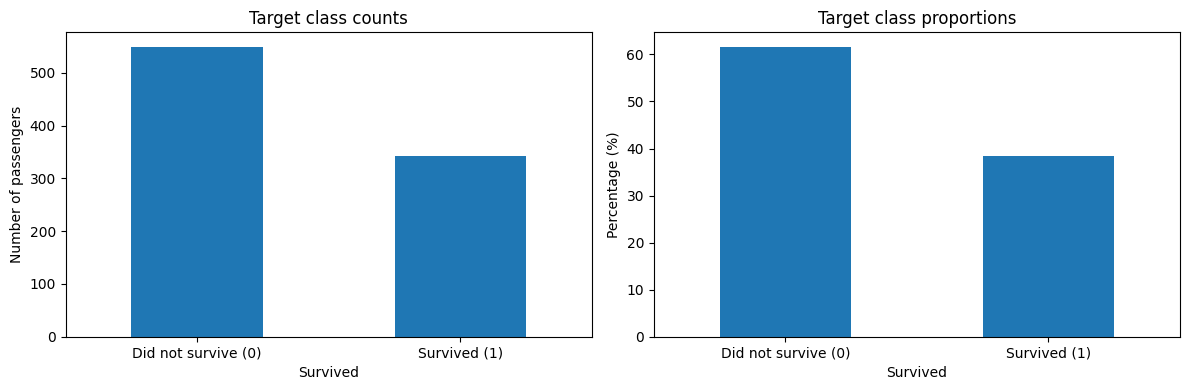

In [3]:
print("Missing values (largest first):")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Survived"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], rot=0
)
axes[0].set_xticks([0, 1], ["Did not survive (0)", "Survived (1)"])
axes[0].set_ylabel("Number of passengers")
axes[0].set_title("Target class counts")

(df["Survived"].value_counts(normalize=True).sort_index() * 100).plot(
    kind="bar", ax=axes[1], rot=0
)
axes[1].set_xticks([0, 1], ["Did not survive (0)", "Survived (1)"])
axes[1].set_ylabel("Percentage (%)")
axes[1].set_title("Target class proportions")
plt.tight_layout()
plt.show()


## 3. Exploratory data visualizations

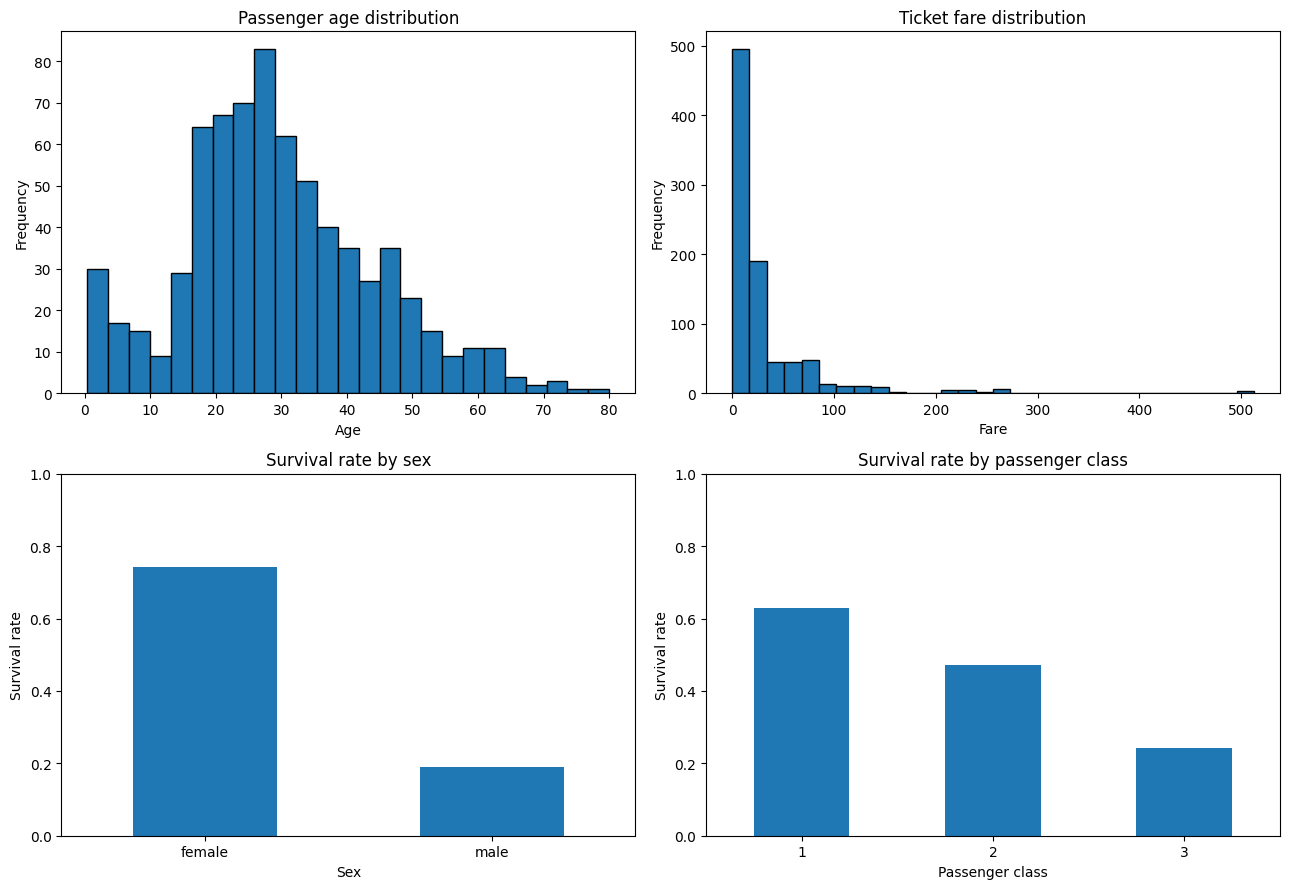

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

df["Age"].dropna().plot(kind="hist", bins=25, ax=axes[0, 0], edgecolor="black")
axes[0, 0].set_title("Passenger age distribution")
axes[0, 0].set_xlabel("Age")

df["Fare"].plot(kind="hist", bins=30, ax=axes[0, 1], edgecolor="black")
axes[0, 1].set_title("Ticket fare distribution")
axes[0, 1].set_xlabel("Fare")

survival_sex = df.groupby("Sex", observed=False)["Survived"].mean()
survival_sex.plot(kind="bar", ax=axes[1, 0], rot=0)
axes[1, 0].set_title("Survival rate by sex")
axes[1, 0].set_ylabel("Survival rate")
axes[1, 0].set_ylim(0, 1)

survival_class = df.groupby("Pclass")["Survived"].mean()
survival_class.plot(kind="bar", ax=axes[1, 1], rot=0)
axes[1, 1].set_title("Survival rate by passenger class")
axes[1, 1].set_xlabel("Passenger class")
axes[1, 1].set_ylabel("Survival rate")
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()


## 4. Select features and split the data

We use a compact set of interpretable features: passenger class, sex, age, number of siblings/spouses, number of parents/children, fare, and port of embarkation. `PassengerId`, `Name`, `Ticket`, and `Cabin` are excluded from this first model; `Cabin` is also heavily missing.

Categorical variables are one-hot encoded. Numeric missing values are imputed with the **training-set median**; categorical missing values use the **training-set most frequent value**. Standardization is fitted only on the training data.

In [10]:
target = df["Survived"].to_numpy(dtype=int)

features = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
n_rows = len(features)
# Create a random number generator
rng = np.random.default_rng(42)

train_indices, test_indices = [], []

for class_value in np.unique(target):
    class_indices = np.where(target == class_value)[0]

    rng.shuffle(class_indices)

    split_point = int(round(0.8 * len(class_indices)))

    train_indices.extend(class_indices[:split_point])
    test_indices.extend(class_indices[split_point:])
train_indices = np.array(train_indices)
test_indices = np.array(test_indices)
rng.shuffle(train_indices)
rng.shuffle(test_indices)

X_train_raw = features.iloc[train_indices].copy()
X_test_raw = features.iloc[test_indices].copy()
y_train = target[train_indices]
y_test = target[test_indices]

numeric_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_cols = ["Sex", "Embarked"]

numeric_medians = {}
for col in numeric_cols:
    numeric_medians[col] = X_train_raw[col].median()
    X_train_raw.loc[:, col] = X_train_raw[col].fillna(numeric_medians[col])
    X_test_raw.loc[:, col] = X_test_raw[col].fillna(numeric_medians[col])

categorical_modes = {}
for col in categorical_cols:
    mode_values = X_train_raw[col].mode(dropna=True)
    mode_value = mode_values.iloc[0]
    categorical_modes[col] = mode_value
    X_train_raw.loc[:, col] = X_train_raw[col].fillna(mode_value)
    X_test_raw.loc[:, col] = X_test_raw[col].fillna(mode_value)

X_train = pd.get_dummies(X_train_raw, columns=categorical_cols, drop_first=True, dtype=float)
X_test = pd.get_dummies(X_test_raw, columns=categorical_cols, drop_first=True, dtype=float)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

numeric_means = X_train[numeric_cols].mean()
numeric_stds = X_train[numeric_cols].std(ddof=0).replace(0, 1)
X_train.loc[:, numeric_cols] = (X_train[numeric_cols] - numeric_means) / numeric_stds
X_test.loc[:, numeric_cols] = (X_test[numeric_cols] - numeric_means) / numeric_stds

feature_names = list(X_train.columns)
X_train = X_train.to_numpy(dtype=float)
X_test = X_test.to_numpy(dtype=float)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (713, 8)
X_test : (178, 8)
y_train: (713,)
y_test : (178,)


C:\Users\yeswa\AppData\Local\Temp\ipykernel_4356\3852121698.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 0.83292504 -0.36682355 -0.36682355  0.83292504  0.83292504  0.83292504
 -1.56657215  0.83292504  0.83292504 -0.36682355  0.83292504 -0.36682355
  0.83292504  0.83292504 -1.56657215  0.83292504  0.83292504  0.83292504
 -1.56657215 -1.56657215  0.83292504  0.83292504  0.83292504 -1.56657215
  0.83292504  0.83292504  0.83292504 -1.56657215  0.83292504  0.83292504
  0.83292504 -0.36682355  0.83292504 -0.36682355 -1.56657215  0.83292504
  0.83292504 -1.56657215 -1.56657215 -1.56657215 -0.36682355  0.83292504
 -0.36682355  0.83292504  0.83292504  0.83292504  0.83292504  0.83292504
  0.83292504  0.83292504  0.83292504  0.83292504 -0.36682355  0.83292504
 -1.56657215  0.83292504  0.83292504 -1.56657215  0.83292504 -0.36682355
  0.83292504 -0.36682355  0.83292504 -1.56657215  0.83292504 -0.36682355
 -0.36682355

## 5. Implement logistic regression with NumPy



The binary cross-entropy loss is minimized using batch gradient descent. The gradients are
Here, the output is a probability; we apply a threshold later to convert it into class predictions.

In [11]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y, probabilities):
    eps = 1e-12
    probabilities = np.clip(probabilities, eps, 1 - eps)
    return -np.mean(
        y * np.log(probabilities) + (1 - y) * np.log(1 - probabilities)
    )

m, n = X_train.shape
w = np.zeros(n, dtype=float)
b = 0.0

learning_rate = 0.05
iterations = 5000
loss_history = []

for i in range(iterations):
    probabilities = sigmoid(X_train @ w + b)
    loss = binary_cross_entropy(y_train, probabilities)
    loss_history.append(loss)

    error = probabilities - y_train
    dw = (X_train.T @ error) / m
    db = np.mean(error)

    w -= learning_rate * dw
    b -= learning_rate * db

print("Training complete")
print("Final training loss:", round(loss_history[-1], 5))
print("Bias:", round(b, 5))
print("Number of weights:", len(w))


Training complete
Final training loss: 0.43794
Bias: 1.47668
Number of weights: 8


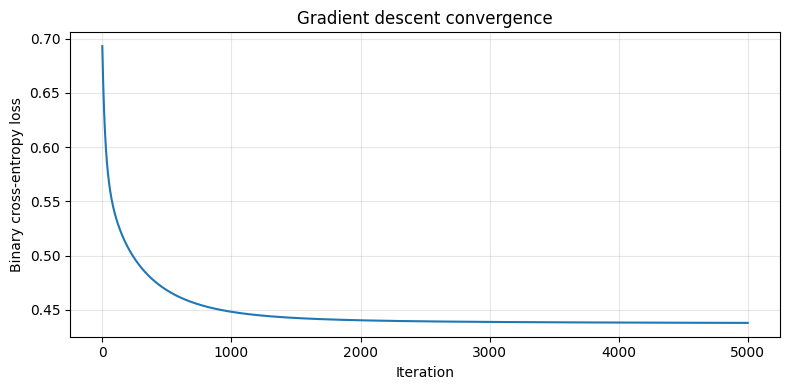

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("Binary cross-entropy loss")
plt.title("Gradient descent convergence")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Generate predictions on the test set

In [13]:
y_test_prob = sigmoid(X_test @ w + b)
threshold = 0.5
y_test_pred = (y_test_prob >= threshold).astype(int)

print("First 10 actual labels:    ", y_test[:10])
print("First 10 predicted labels: ", y_test_pred[:10])
print("First 10 survival probs:   ", np.round(y_test_prob[:10], 3))


First 10 actual labels:     [0 0 0 0 0 1 1 0 0 0]
First 10 predicted labels:  [0 0 0 0 0 1 1 0 0 0]
First 10 survival probs:    [0.051 0.07  0.317 0.121 0.122 0.668 0.744 0.065 0.095 0.122]


## 7. Classification metrics

Accuracy measures the overall fraction classified correctly. **Precision** measures how often predicted survivors actually survived; **recall** measures how many actual survivors were found; **F1** balances precision and recall. ROC-AUC measures ranking quality across thresholds. Because false negatives and false positives have different implications, do not judge the model using accuracy alone.

In [14]:

tp = np.sum((y_test == 1) & (y_test_pred == 1))
tn = np.sum((y_test == 0) & (y_test_pred == 0))
fp = np.sum((y_test == 0) & (y_test_pred == 1))
fn = np.sum((y_test == 1) & (y_test_pred == 0))

accuracy = (tp + tn) / len(y_test)
precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0

eps = 1e-12
prob_clipped = np.clip(y_test_prob, eps, 1 - eps)
logloss = -np.mean(y_test * np.log(prob_clipped) + (1 - y_test) * np.log(1 - prob_clipped))

positive_scores = y_test_prob[y_test == 1]
negative_scores = y_test_prob[y_test == 0]
comparisons = positive_scores[:, None] - negative_scores[None, :]
roc_auc = (np.sum(comparisons > 0) + 0.5 * np.sum(comparisons == 0)) / comparisons.size

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 score", "ROC-AUC", "Log loss"],
    "Value": [accuracy, precision, recall, f1, roc_auc, logloss]
})
display(metrics.style.format({"Value": "{:.4f}"}))

print("Class 0 (did not survive):")
print("  Precision:", round(tn / (tn + fn), 4) if (tn + fn) else 0.0)
print("  Recall:   ", round(tn / (tn + fp), 4) if (tn + fp) else 0.0)
print("  F1-score: ", round(
    2 * (tn / (tn + fn)) * (tn / (tn + fp)) /
    ((tn / (tn + fn)) + (tn / (tn + fp))), 4
) if (tn + fn) and (tn + fp) and ((tn / (tn + fn)) + (tn / (tn + fp))) else 0.0)
print("Class 1 (survived):")
print("  Precision:", round(precision, 4))
print("  Recall:   ", round(recall, 4))
print("  F1-score: ", round(f1, 4))


,Metric,Value
0,Accuracy,0.7753
1,Precision,0.7414
2,Recall,0.6324
3,F1 score,0.6825
4,ROC-AUC,0.8471
5,Log loss,0.4556


Class 0 (did not survive):
  Precision: 0.7917
  Recall:    0.8636
  F1-score:  0.8261
Class 1 (survived):
  Precision: 0.7414
  Recall:    0.6324
  F1-score:  0.6825


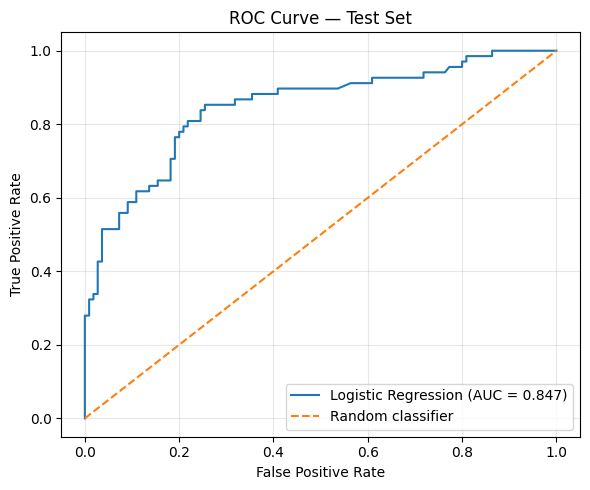

ROC-AUC: 0.8471


In [19]:

thresholds = np.r_[
    np.inf,
    np.sort(np.unique(y_test_prob))[::-1],
    -np.inf
]

fpr_values = []
tpr_values = []

for threshold in thresholds:
    y_pred_temp = (y_test_prob >= threshold).astype(int)

    tp = np.sum((y_test == 1) & (y_pred_temp == 1))
    tn = np.sum((y_test == 0) & (y_pred_temp == 0))
    fp = np.sum((y_test == 0) & (y_pred_temp == 1))
    fn = np.sum((y_test == 1) & (y_pred_temp == 0))

    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    tpr_values.append(tpr)
    fpr_values.append(fpr)

roc_points = (
    pd.DataFrame({"fpr": fpr_values, "tpr": tpr_values})
    .drop_duplicates()
    .sort_values("fpr")
)

x = roc_points["fpr"].to_numpy()
y = roc_points["tpr"].to_numpy()

auc_trapezoid = np.sum(
    (x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2
)

plt.figure(figsize=(6, 5))
plt.plot(
    x, y,
    label=f"Logistic Regression (AUC = {auc_trapezoid:.3f})"
)
plt.plot([0, 1], [0, 1], "--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Test Set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC:", round(auc_trapezoid, 4))


## 8. Predicted probability distributions

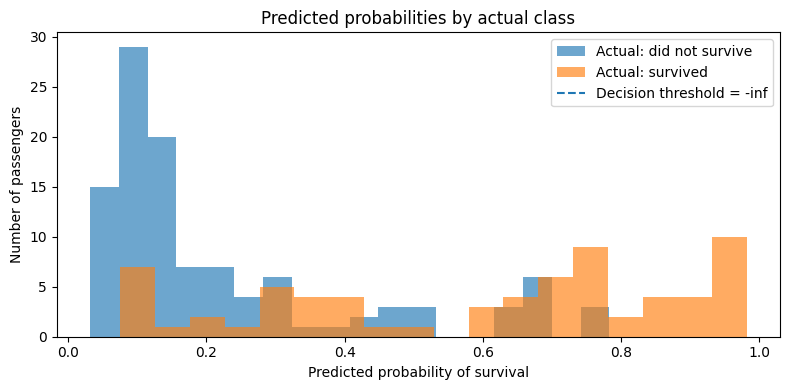

In [20]:
plt.figure(figsize=(8, 4))
plt.hist(y_test_prob[y_test == 0], bins=18, alpha=0.65, label="Actual: did not survive")
plt.hist(y_test_prob[y_test == 1], bins=18, alpha=0.65, label="Actual: survived")
plt.axvline(threshold, linestyle="--", label=f"Decision threshold = {threshold}")
plt.xlabel("Predicted probability of survival")
plt.ylabel("Number of passengers")
plt.title("Predicted probabilities by actual class")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Inspect learned coefficients

Coefficients are on standardized numeric features and one-hot encoded categories. A positive coefficient increases the log-odds of survival, holding the other features fixed; a negative coefficient decreases them. Coefficients describe this fitted model and should not automatically be interpreted as causal effects.

,Feature,Coefficient
5,Sex_male,-2.752938
0,Pclass,-0.830801
7,Embarked_S,-0.473092
1,Age,-0.433728
2,SibSp,-0.324571
6,Embarked_Q,-0.209166
3,Parch,-0.110188
4,Fare,0.123682


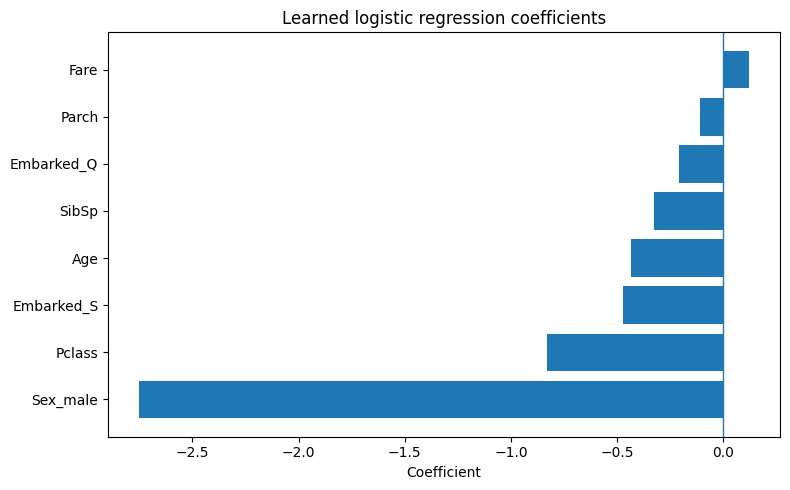

In [21]:

coef_table = pd.DataFrame({"Feature": feature_names, "Coefficient": w})
coef_table = coef_table.sort_values("Coefficient")
display(coef_table)

plt.figure(figsize=(8, 5))
plt.barh(coef_table["Feature"], coef_table["Coefficient"])
plt.axvline(0, linewidth=1)
plt.xlabel("Coefficient")
plt.title("Learned logistic regression coefficients")
plt.tight_layout()
plt.show()


## 10. Interpretation and limitations

- The metrics are calculated on a held-out 20% test split; results can vary with the split.
- The 0.5 threshold is a default, not necessarily the best threshold for every objective.